# Event metadata

Besides its onset and label, an event often comes with more information: the trial it belongs to, the condition, the choice, the reward or the reaction time. In `pypillometry`, this information is stored as *metadata* of the events: columns with one value per event. The events can then be selected by their metadata, and the metadata are passed on to intervals and segments.

There are two common sources of metadata:

1. **The trigger labels.** Many experiments code the information in the triggers that are sent to the eye tracker, e.g., `S_12_3_5` for the stimulus of trial 12 with the symbols 3 and 5. The labels are decomposed into metadata with `parse_labels()`.
2. **A behaviour log.** The experiment software writes a table with one row per trial. `Events.from_table()` creates the events from its time columns and takes the other columns as metadata.

This tutorial shows both cases, how to select events by their metadata and how to use the metadata in an analysis.

In [1]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

d = pp.get_example_data("rlmw_002_short")
d = d.pupil_blinks_detect(vel_onset=-15, apply_mask=True)\
     .blinks_merge_close(distance=100 * u.ms, apply_mask=True)\
     .pupil_blinks_interpolate(margin=(50, 150) * u.ms)\
     .pupil_lowpass_filter(cutoff=5)

## Metadata from trigger labels

The example data are from a reinforcement-learning task. In each trial, a fixation cross was shown (`F_<trial>`), then two symbols (`S_<trial>_<left symbol>_<right symbol>`). The participant chose one of them (`C_<trial>_<chosen symbol>_<side>`, side 1 is left and 2 is right) and got a reward (`R_<trial>_<points>`):

In [2]:
events = d.get_events()
events[:8]

,Onset (ms),Label
0,5177.0,F_1
1,5677.0,S_1_1_5
2,6773.0,C_1_5_2
3,7010.0,R_1_15
4,8776.0,F_2
5,9575.0,S_2_6_2
6,10581.0,C_2_6_1
7,10808.0,R_2_20


`parse_labels()` takes a regular expression with *named groups*, `(?P<name>...)`. Each group becomes a metadata column. For events whose label does not match, the value is missing (NaN for numbers, `""` for text). Columns that contain only numbers are converted to numbers:

In [3]:
ev = events.parse_labels(r"^[FSCR]_(?P<trial>\d+)")
ev[:8]

,Onset (ms),Label,trial
0,5177.0,F_1,1
1,5677.0,S_1_1_5,1
2,6773.0,C_1_5_2,1
3,7010.0,R_1_15,1
4,8776.0,F_2,2
5,9575.0,S_2_6_2,2
6,10581.0,C_2_6_1,2
7,10808.0,R_2_20,2


Each call adds columns, so the different kinds of events can be parsed one after the other:

In [4]:
ev = (ev.parse_labels(r"^S_\d+_(?P<left>\d+)_(?P<right>\d+)")
        .parse_labels(r"^C_\d+_(?P<chosen>\d+)_(?P<side>\d+)")
        .parse_labels(r"^R_\d+_(?P<reward>\d+)"))
ev[:8]

,Onset (ms),Label,trial,left,right,chosen,side,reward
0,5177.0,F_1,1,NaN,NaN,NaN,NaN,NaN
1,5677.0,S_1_1_5,1,1.0,5.0,NaN,NaN,NaN
2,6773.0,C_1_5_2,1,NaN,NaN,5.0,2.0,NaN
3,7010.0,R_1_15,1,NaN,NaN,NaN,NaN,15.0
4,8776.0,F_2,2,NaN,NaN,NaN,NaN,NaN
5,9575.0,S_2_6_2,2,6.0,2.0,NaN,NaN,NaN
6,10581.0,C_2_6_1,2,NaN,NaN,6.0,1.0,NaN
7,10808.0,R_2_20,2,NaN,NaN,NaN,NaN,20.0


Instead of a regular expression, `parse_labels()` also takes a function. It gets a label and returns a dict with the metadata of this event (or `None` for no metadata). This is often easier for more complex codes. The following function gives the same result as the four regular expressions above:

In [5]:
def parse(label):
    kind, trial, *numbers = label.split("_")
    names = {"F": [], "S": ["left", "right"], "C": ["chosen", "side"], "R": ["reward"]}
    return {"trial": int(trial), **dict(zip(names[kind], map(int, numbers)))}

ev = events.parse_labels(parse)
ev[:8]

,Onset (ms),Label,trial,left,right,chosen,side,reward
0,5177.0,F_1,1,NaN,NaN,NaN,NaN,NaN
1,5677.0,S_1_1_5,1,1.0,5.0,NaN,NaN,NaN
2,6773.0,C_1_5_2,1,NaN,NaN,5.0,2.0,NaN
3,7010.0,R_1_15,1,NaN,NaN,NaN,NaN,15.0
4,8776.0,F_2,2,NaN,NaN,NaN,NaN,NaN
5,9575.0,S_2_6_2,2,6.0,2.0,NaN,NaN,NaN
6,10581.0,C_2_6_1,2,NaN,NaN,6.0,1.0,NaN
7,10808.0,R_2_20,2,NaN,NaN,NaN,NaN,20.0


The metadata are stored in `meta`, a dict with one numpy array per column. `row()` returns all information about one event:

In [6]:
print(list(ev.meta))
print(ev.meta["reward"][:8])
ev.row(1)

['trial', 'left', 'right', 'chosen', 'side', 'reward']
[nan nan nan 15. nan nan nan 20.]


{'onset': 5677.0,
 'label': 'S_1_1_5',
 'trial': 1,
 'left': 1.0,
 'right': 5.0,
 'chosen': nan,
 'side': nan,
 'reward': nan}

## Information from other events of the trial

Each column is filled only for the events whose label contains the information. To select the stimuli by the choice or the reward that followed, these values are needed at the stimulus events. `fill_meta()` copies them to all events with the same value in another column, here the trial number:

In [7]:
ev = ev.fill_meta(["chosen", "side", "reward"], by="trial")
ev[:8]

,Onset (ms),Label,trial,left,right,chosen,side,reward
0,5177.0,F_1,1,NaN,NaN,5.0,2.0,15.0
1,5677.0,S_1_1_5,1,1.0,5.0,5.0,2.0,15.0
2,6773.0,C_1_5_2,1,NaN,NaN,5.0,2.0,15.0
3,7010.0,R_1_15,1,NaN,NaN,5.0,2.0,15.0
4,8776.0,F_2,2,NaN,NaN,6.0,1.0,20.0
5,9575.0,S_2_6_2,2,6.0,2.0,6.0,1.0,20.0
6,10581.0,C_2_6_1,2,NaN,NaN,6.0,1.0,20.0
7,10808.0,R_2_20,2,NaN,NaN,6.0,1.0,20.0


Times between events can be added with `add_latency()`. For example, the reaction time is the time from each stimulus to the choice of the same trial. It is stored at the stimulus events (in the units of the events, here ms):

In [8]:
ev = ev.add_latency("S_", "C_", "rt", by="trial")
ev.filter("S_")

,Onset (ms),Label,trial,left,right,chosen,side,reward,rt
0,5677.0,S_1_1_5,1,1.0,5.0,5.0,2.0,15.0,1096.0
1,9575.0,S_2_6_2,2,6.0,2.0,6.0,1.0,20.0,1006.0
2,12574.0,S_3_2_1,3,2.0,1.0,2.0,1.0,18.0,1159.0
3,16473.0,S_4_4_1,4,4.0,1.0,1.0,2.0,11.0,1116.0
4,20388.0,S_5_3_5,5,3.0,5.0,5.0,2.0,17.0,768.0
5,23987.0,S_6_4_5,6,4.0,5.0,5.0,2.0,20.0,929.0
6,27002.0,S_7_3_1,7,3.0,1.0,1.0,2.0,6.0,1114.0
7,30601.0,S_8_6_5,8,6.0,5.0,6.0,1.0,18.0,907.0
8,34799.0,S_9_4_6,9,4.0,6.0,6.0,2.0,19.0,901.0
9,38415.0,S_10_2_5,10,2.0,5.0,5.0,2.0,18.0,997.0


Without `by`, each first event is paired with the next second event after it, as in `get_intervals()` with two events. First events without a second event (e.g., no response) get NaN.

## Selecting events by metadata

`filter()` takes criteria for metadata columns as keyword arguments, in addition to the selectors for the labels (see the [events tutorial](events.ipynb)). All criteria must be met. A value selects the events where the column is equal to it:

In [9]:
ev.filter("S_", side=1)

,Onset (ms),Label,trial,left,right,chosen,side,reward,rt
0,9575.0,S_2_6_2,2,6.0,2.0,6.0,1.0,20.0,1006.0
1,12574.0,S_3_2_1,3,2.0,1.0,2.0,1.0,18.0,1159.0
2,30601.0,S_8_6_5,8,6.0,5.0,6.0,1.0,18.0,907.0


A list selects the events where the column has one of the values, and a function gets the whole column and returns `True` for the events to keep:

In [10]:
ev.filter("S_", trial=[1, 2, 3])

,Onset (ms),Label,trial,left,right,chosen,side,reward,rt
0,5677.0,S_1_1_5,1,1.0,5.0,5.0,2.0,15.0,1096.0
1,9575.0,S_2_6_2,2,6.0,2.0,6.0,1.0,20.0,1006.0
2,12574.0,S_3_2_1,3,2.0,1.0,2.0,1.0,18.0,1159.0


In [11]:
ev.filter("S_", rt=lambda rt: rt < 1000)

,Onset (ms),Label,trial,left,right,chosen,side,reward,rt
0,20388.0,S_5_3_5,5,3.0,5.0,5.0,2.0,17.0,768.0
1,23987.0,S_6_4_5,6,4.0,5.0,5.0,2.0,20.0,929.0
2,30601.0,S_8_6_5,8,6.0,5.0,6.0,1.0,18.0,907.0
3,34799.0,S_9_4_6,9,4.0,6.0,6.0,2.0,19.0,901.0
4,38415.0,S_10_2_5,10,2.0,5.0,5.0,2.0,18.0,997.0


A boolean array with one value per event works as well, which is useful for criteria that combine several columns:

In [12]:
stim = ev.filter("S_")
stim.filter(stim.meta["chosen"] == stim.meta["left"])   # chose the left symbol

,Onset (ms),Label,trial,left,right,chosen,side,reward,rt
0,9575.0,S_2_6_2,2,6.0,2.0,6.0,1.0,20.0,1006.0
1,12574.0,S_3_2_1,3,2.0,1.0,2.0,1.0,18.0,1159.0
2,30601.0,S_8_6_5,8,6.0,5.0,6.0,1.0,18.0,907.0


New columns can also be set directly with `set_meta()`, for all events or only for selected ones. Here, we mark the trials with a high reward (above the median):

In [13]:
high = ev.meta["reward"] > np.nanmedian(ev.meta["reward"])
ev = ev.set_meta("high_reward", high)
ev.filter("R_")

,Onset (ms),Label,trial,left,right,chosen,side,reward,rt,high_reward
0,7010.0,R_1_15,1,NaN,NaN,5.0,2.0,15.0,NaN,False
1,10808.0,R_2_20,2,NaN,NaN,6.0,1.0,20.0,NaN,True
2,13957.0,R_3_18,3,NaN,NaN,2.0,1.0,18.0,NaN,False
3,17822.0,R_4_11,4,NaN,NaN,1.0,2.0,11.0,NaN,False
4,21388.0,R_5_17,5,NaN,NaN,5.0,2.0,17.0,NaN,False
5,25153.0,R_6_20,6,NaN,NaN,5.0,2.0,20.0,NaN,True
6,28352.0,R_7_6,7,NaN,NaN,1.0,2.0,6.0,NaN,False
7,31734.0,R_8_18,8,NaN,NaN,6.0,1.0,18.0,NaN,False
8,35932.0,R_9_19,9,NaN,NaN,6.0,2.0,19.0,NaN,True
9,39648.0,R_10_18,10,NaN,NaN,5.0,2.0,18.0,NaN,False


## Storing the metadata in the data

`set_events()` stores the events with their metadata in the dataset. They are kept when the data are cropped and are saved with `write_file()`:

In [14]:
d.set_events(ev)
d.get_events()

,Onset (ms),Label,trial,left,right,chosen,side,reward,rt,high_reward
0,5177.0,F_1,1,NaN,NaN,5.0,2.0,15.0,NaN,False
1,5677.0,S_1_1_5,1,1.0,5.0,5.0,2.0,15.0,1096.0,False
2,6773.0,C_1_5_2,1,NaN,NaN,5.0,2.0,15.0,NaN,False
3,7010.0,R_1_15,1,NaN,NaN,5.0,2.0,15.0,NaN,False
4,8776.0,F_2,2,NaN,NaN,6.0,1.0,20.0,NaN,True
5,9575.0,S_2_6_2,2,6.0,2.0,6.0,1.0,20.0,1006.0,True
6,10581.0,C_2_6_1,2,NaN,NaN,6.0,1.0,20.0,NaN,True
7,10808.0,R_2_20,2,NaN,NaN,6.0,1.0,20.0,NaN,True
8,12374.0,F_3,3,NaN,NaN,2.0,1.0,18.0,NaN,False
9,12574.0,S_3_2_1,3,2.0,1.0,2.0,1.0,18.0,1159.0,False


## Metadata in intervals and segments

`get_intervals()` passes the metadata of the selected events on to the intervals (`event_meta`). Together with `stat_per_event()`, this gives a table with one row per event, ready for statistical analysis:

In [15]:
iv = d.get_intervals("R_", window=(0, 1500) * u.ms)
pupil = d.stat_per_event(intervals=iv, eyes="left", variables="pupil")

table = iv.as_pandas()
table["pupil"] = pupil["left_pupil"]
table[["event_label", "trial", "reward", "high_reward", "pupil"]]

,event_label,trial,reward,high_reward,pupil
0,R_1_15,1,15.0,False,1174.087240
1,R_2_20,2,20.0,True,1208.897667
2,R_3_18,3,18.0,False,1162.184876
3,R_4_11,4,11.0,False,1178.507409
4,R_5_17,5,17.0,False,1118.242396
5,R_6_20,6,20.0,True,1055.722909
6,R_7_6,7,6.0,False,1098.455658
7,R_8_18,8,18.0,False,1185.117722
8,R_9_19,9,19.0,True,1071.796288
9,R_10_18,10,18.0,False,1070.726008


For example, the mean pupil size after high and low rewards:

In [16]:
table.groupby("high_reward").pupil.mean()

high_reward
False    1141.045901
True     1112.138955
Name: pupil, dtype: float64

To get the segments of one condition, e.g., for an event-related pupil dilation (see the [ERPD tutorial](erpds.ipynb)), select the events by their metadata before getting the intervals:

SegmentedEyeData(events_3):
  variable      : left_pupil
  n_segments    : 3
  n_timepoints  : 1000
  window        : (np.float64(-500.0), np.float64(1500.0))
  percent_masked: 18.17
  sampling_rate : 500.00
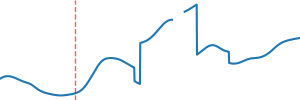

In [17]:
feedback = d.get_events().filter("R_")
iv_high = d.get_intervals(feedback.filter(high_reward=True), window=(-500, 1500) * u.ms)
seg_high = d.get_segments(iv_high, "left_pupil").baseline_correct(window=(-200, 0))
seg_high

The segments keep their intervals, so the metadata of each segment are in `seg_high.intervals.event_meta`.

## Metadata from a behaviour log

When the information is in a behaviour log instead, `Events.from_table()` takes the columns with metadata as `meta`. Every event of a row gets the values of that row. Here is a small made-up log with one row per trial (times in seconds):

In [18]:
behav = pd.DataFrame({"trial": [1, 2, 3],
                      "cond": ["easy", "hard", "easy"],
                      "stim_on": [12.531, 15.704, 18.877],
                      "rt": [0.412, np.nan, 0.538]})

ev_log = pp.Events.from_table(behav, {"stim": "stim_on",
                                      "response": behav.stim_on + behav.rt},
                              units="sec", meta=["trial", "cond", "rt"])
ev_log

,Onset (sec),Label,trial,cond,rt,row
0,12.531,stim,1,easy,0.412,0
1,12.943,response,1,easy,0.412,0
2,15.704,stim,2,hard,NaN,1
3,18.877,stim,3,easy,0.538,2
4,19.415,response,3,easy,0.538,2


The column `row` gives the row of the table that each event came from (use `row=None` to leave it out). It links the events of the same row even if the table has no trial number.

The events are still on the clock of the experiment computer. They are mapped to the eye-tracker clock with `sync_clocks()` and added to the data with `add_events()`, as shown in the tutorial [Events from a behaviour log](importdata_behaviour.ipynb); both keep the metadata. Events that do not have a column (e.g., the triggers that were already in the recording) get missing values in it.

## Exporting the metadata

`to_table()` returns the events with their metadata as a dict of columns, which can be turned into a `pandas.DataFrame` (pandas is not needed for the metadata themselves):

In [19]:
pd.DataFrame(d.get_events().to_table()).head()

,onset,label,trial,left,right,chosen,side,reward,rt,high_reward
0,5177.0,F_1,1,NaN,NaN,5.0,2.0,15.0,NaN,False
1,5677.0,S_1_1_5,1,1.0,5.0,5.0,2.0,15.0,1096.0,False
2,6773.0,C_1_5_2,1,NaN,NaN,5.0,2.0,15.0,NaN,False
3,7010.0,R_1_15,1,NaN,NaN,5.0,2.0,15.0,NaN,False
4,8776.0,F_2,2,NaN,NaN,6.0,1.0,20.0,NaN,True
